In [ ]:
%pip install "opencv-python-headless>=4,<5"

In [ ]:
import cv2

detector = cv2.CascadeClassifier(
    cv2.data.haarcascades + "haarcascade_frontalface_default.xml"
)
print("OpenCV version:", cv2.__version__)
print("Face detector ready:", not detector.empty())

OpenCV version: 4.14.0
Face detector ready: True


In [ ]:
import csv
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from PIL import Image, ImageOps


def sample_cheeks(face):
    height, width = face.shape[:2]
    top, bottom = int(0.55 * height), int(0.68 * height)
    boxes = [
        (int(0.12 * width), top, int(0.30 * width), bottom),
        (int(0.70 * width), top, int(0.88 * width), bottom),
    ]

    patches = [face[y1:y2, x1:x2] for x1, y1, x2, y2 in boxes]
    pixels = np.concatenate([patch.reshape(-1, 3) for patch in patches])
    rgb = np.median(pixels, axis=0).astype(np.uint8)

    lab = cv2.cvtColor(rgb.reshape(1, 1, 3), cv2.COLOR_RGB2LAB)
    lightness = int(lab[0, 0, 0])
    depth = "light" if lightness >= 175 else "medium" if lightness >= 115 else "dark"

    result = {
        "rgb": rgb.tolist(),
        "hex": "#{:02x}{:02x}{:02x}".format(*rgb),
        "lab_lightness_8bit": lightness,
        "estimated_depth": depth,
    }
    return result, boxes


def analyze_photo(path):
    with Image.open(path) as photo:
        image = np.asarray(ImageOps.exif_transpose(photo).convert("RGB"))

    gray = cv2.cvtColor(image, cv2.COLOR_RGB2GRAY)
    faces = detector.detectMultiScale(gray, 1.1, 5, minSize=(40, 40))
    if len(faces) == 0:
        raise ValueError("No face detected. Try a front-facing photo.")

    x, y, w, h = max(faces, key=lambda box: box[2] * box[3])
    face = image[y:y + h, x:x + w]
    result, boxes = sample_cheeks(face)
    return result, face, boxes


print("Photo analysis functions ready.")

Photo analysis functions ready.


Saving Photo on 24-11-26 at 10.40 AM.jpg to Photo on 24-11-26 at 10.40 AM.jpg


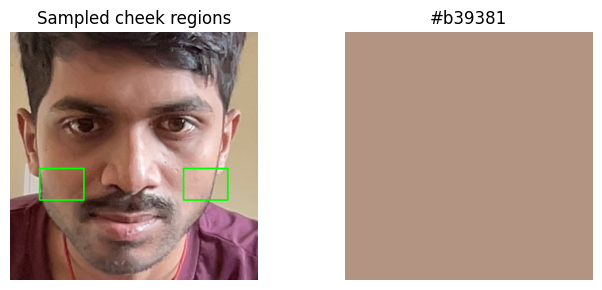

Estimated depth in this photo: medium
RGB: [179, 147, 129]


In [ ]:
from google.colab import files

uploaded = files.upload()
if uploaded:
    photo_path = next(iter(uploaded))
    result, face, boxes = analyze_photo(photo_path)

    preview = face.copy()
    for x1, y1, x2, y2 in boxes:
        cv2.rectangle(preview, (x1, y1), (x2 - 1, y2 - 1), (0, 255, 0), 2)

    fig, axes = plt.subplots(1, 2, figsize=(7, 3))
    axes[0].imshow(preview)
    axes[0].set_title("Sampled cheek regions")
    swatch = np.full((80, 80, 3), result["rgb"], dtype=np.uint8)
    axes[1].imshow(swatch)
    axes[1].set_title(result["hex"])
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

    print("Estimated depth in this photo:", result["estimated_depth"])
    print("RGB:", result["rgb"])
else:
    print("Run this cell again and choose a photo.")

In [ ]:
import json

record = {
    "photo": Path(photo_path).name,
    "method": "Median cheek RGB with Lab lightness thresholds",
    **result,
}

output = Path(f"{Path(photo_path).stem}_skin_tone.json")
output.write_text(json.dumps(record, indent=2), encoding="utf-8")
print(output.read_text())
files.download(str(output))

{
  "photo": "Photo on 24-11-26 at 10.40\u202fAM.jpg",
  "method": "Median cheek RGB with Lab lightness thresholds",
  "rgb": [
    179,
    147,
    129
  ],
  "hex": "#b39381",
  "lab_lightness_8bit": 162,
  "estimated_depth": "medium"
}


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>